In [1]:
import sys
sys.path.append("..")  # le notebook est dans notebooks/, src/ est au niveau au-dessus

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.curves.data import charger_courbe
from src.curves.nelson_siegel import ns_rate, fit_ns

In [2]:
courbe = charger_courbe("../data/raw/yield_curve.csv")
T = courbe.columns.values # les 197 maturités en années
y = courbe.loc["2026-10-28"].values # les 197 taux de cette date

res = fit_ns(T, y)
print(res.success, res.message) #vérifie la convergence
print(res.x)               # [beta0, beta1, beta2, tau]

True `ftol` termination condition is satisfied.
[-0.07406785  0.10179909  0.16785115 37.1801297 ]


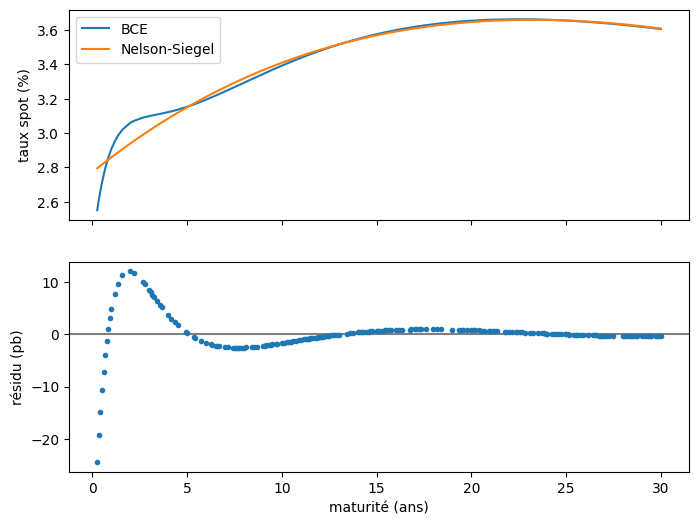

In [3]:
fit = ns_rate(T, *res.x) #on test avec les paramètres optimaux, 
residus_pb = (y - fit) * 1e4      # convention observé - modèle, en pb

fig, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
ax[0].plot(T, y * 100, label="BCE")
ax[0].plot(T, fit * 100, label="Nelson-Siegel")
ax[0].set_ylabel("taux spot (%)")
ax[0].legend()
ax[1].axhline(0, color="gray")
ax[1].plot(T, residus_pb, ".")
ax[1].set_ylabel("résidu (pb)")
ax[1].set_xlabel("maturité (ans)")
plt.show()